In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [11]:
df = pd.read_csv('/content/Indian Rainfall Dataset District-wise Daily Measurements.csv', sep=';')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("Column names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (8790, 34)


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.205834,0.671002,0.028994,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.615237,0.925098,0.507623,0.424843,0.737394,0.0,0.0,0.0


Column names:
['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']


In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
state       2270
district    2270
month       2270
1st         2270
2nd         2270
3rd         2270
4th         2270
5th         2270
6th         2270
7th         2270
dtype: int64

Total missing values: 22700


In [13]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Fill missing numeric values with column means
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].mean()
)

# Fill missing text values with the most frequent value
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled!")
print(df.isnull().sum())

Missing values handled!
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64


In [14]:
# Slice the dataframe to include columns from 'state' to '7th'
columns_to_keep = ['state', 'district', 'month', '1st', '2nd', '3rd', '4th', '5th', '6th', '7th']
df_reduced = df[columns_to_keep]

print("Reduced dataset shape:", df_reduced.shape)
display(df_reduced.head())

Reduced dataset shape: (8790, 10)


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.379965,0.000000,0.0,0.0,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,14.144900,0.857263,0.0,0.0,0.0,0.0,0.0


In [15]:
# Identify numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Fill missing numeric values with column means
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].mean()
)

# Fill missing text values with the most frequent value
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled!")
print(df.isnull().sum())

Missing values handled!
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64


In [16]:
# Identify daily rainfall measurement columns
rainfall_cols = [
    col for col in df.columns
    if col.lower().endswith(('st', 'nd', 'rd', 'th'))
    and col[:-2].isdigit()
]

print("Rainfall columns:", rainfall_cols)

# Convert rainfall columns to numeric
for col in rainfall_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing rainfall values using each column's mean
if rainfall_cols:
    df[rainfall_cols] = df[rainfall_cols].fillna(
        df[rainfall_cols].mean()
    )

    # Normalize rainfall values
    scaler = MinMaxScaler()
    df[rainfall_cols] = scaler.fit_transform(
        df[rainfall_cols]
    )

    print("Rainfall measurements normalized successfully!")
else:
    print("No daily rainfall columns detected. Check the column names.")

Rainfall columns: ['1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th', '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th', '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th', '29th', '30th', '31st']
Rainfall measurements normalized successfully!


In [17]:
print("Processed dataset:")
display(df.head())

print("\nRemaining missing values:")
print(df.isnull().sum())

if rainfall_cols:
    print("\nNormalized rainfall measurements:")
    display(df[rainfall_cols].head())

    print("\nMinimum normalized value:",
          df[rainfall_cols].min().min())

    print("Maximum normalized value:",
          df[rainfall_cols].max().max())

Processed dataset:


,state,district,month,1st,2nd,3rd,4th,5th,6th,7th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,Andaman & Nicobar,Nicobars,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,Andaman & Nicobar,North And Middle Andaman,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,Andaman & Nicobar,South Andamans,1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,Andhra Pradesh,Anantapur,1,0.001741,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000696,0.005371,0.000173,0.0,0.0,0.0
4,Andhra Pradesh,Chittoor,1,0.064794,0.002665,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.004573,0.008129,0.001717,0.003401,0.004410,0.0,0.0,0.0



Remaining missing values:
state       0
district    0
month       0
1st         0
2nd         0
3rd         0
4th         0
5th         0
6th         0
7th         0
8th         0
9th         0
10th        0
11th        0
12th        0
13th        0
14th        0
15th        0
16th        0
17th        0
18th        0
19th        0
20th        0
21st        0
22nd        0
23rd        0
24th        0
25th        0
26th        0
27th        0
28th        0
29th        0
30th        0
31st        0
dtype: int64

Normalized rainfall measurements:


,1st,2nd,3rd,4th,5th,6th,7th,8th,9th,10th,...,22nd,23rd,24th,25th,26th,27th,28th,29th,30th,31st
0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
3,0.001741,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.000000,0.000000,0.000696,0.005371,0.000173,0.0,0.0,0.0
4,0.064794,0.002665,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.004573,0.008129,0.001717,0.003401,0.004410,0.0,0.0,0.0



Minimum normalized value: 0.0
Maximum normalized value: 1.0


In [20]:
import pandas as pd
import numpy as np

# Load correct file with proper delimiter
df = pd.read_csv('/content/Indian Rainfall Dataset District-wise Daily Measurements.csv', sep=';')
df.columns = df.columns.str.strip().str.lower()

district = 'Coimbatore'
df = df[df['district'].astype(str).str.strip().str.lower() == district.lower()].copy()

# Identify daily measurement columns only up to the 7th day
target_days = ['1st', '2nd', '3rd', '4th', '5th', '6th', '7th']
day_cols = [c for c in df.columns if c in target_days]

# Convert monthly rows to daily rows
daily = df.melt(
    id_vars=['month'],
    value_vars=day_cols,
    var_name='day',
    value_name='rainfall'
)

daily['day'] = daily['day'].str[:-2].astype(int)
daily['rainfall'] = pd.to_numeric(daily['rainfall'], errors='coerce')

# Convert month names or numbers to month numbers
daily['month'] = daily['month'].apply(
    lambda x: int(x) if str(x).isdigit()
    else pd.to_datetime(str(x), format='%B').month
)

daily['date'] = pd.to_datetime({
    'year': 2022,
    'month': daily['month'],
    'day': daily['day']
}, errors='coerce')

daily = daily.dropna(subset=['date'])
daily = daily.dropna(subset=['rainfall'])
daily = daily[daily['rainfall'] >= 0]
daily = daily.sort_values('date').drop_duplicates('date')

print("District:", district)
print("Daily records (up to 7th day of each month):", len(daily))
display(daily[['date', 'rainfall']].head(10))

District: Coimbatore
Daily records (up to 7th day of each month): 84


,date,rainfall
0,2022-01-01,2.148890
12,2022-01-02,9.110140
24,2022-01-03,0.046436
36,2022-01-04,0.000000
48,2022-01-05,0.000000
60,2022-01-06,0.000000
72,2022-01-07,0.000000
1,2022-02-01,0.000000
13,2022-02-02,0.000000
25,2022-02-03,0.000000


In [21]:

from sklearn.preprocessing import MinMaxScaler

values = daily['rainfall'].to_numpy().reshape(-1, 1)
dates = daily['date'].to_numpy()

if len(values) < 10:
    raise ValueError("Not enough rainfall records. Check the district and CSV.")

# Chronological 80:20 split before fitting the scaler
split_point = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split_point])
scaled = scaler.transform(values)

X, y, target_dates = [], [], []

for i in range(7, len(scaled)):
    X.append(scaled[i-7:i])
    y.append(scaled[i, 0])
    target_dates.append(dates[i])

X = np.array(X)
y = np.array(y)
target_dates = np.array(target_dates)

# RNN expects: samples, time steps, features
test_start = split_point - 7

X_train, X_test = X[:test_start], X[test_start:]
y_train, y_test = y[:test_start], y[test_start:]
test_dates = target_dates[test_start:]

print("Input shape:", X.shape)
print("Training sequences:", len(X_train))
print("Testing sequences:", len(X_test))


Input shape: (77, 7, 1)
Training sequences: 60
Testing sequences: 17


In [22]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

model = Sequential([
    SimpleRNN(16, activation='tanh',
              input_shape=(7, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)


Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - loss: 0.0797 - val_loss: 0.0825
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0727 - val_loss: 0.0743
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0673 - val_loss: 0.0653
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0627 - val_loss: 0.0567
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0589 - val_loss: 0.0493
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0556 - val_loss: 0.0435
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0529 - val_loss: 0.0395
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0507 - val_loss: 0.0367
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0488 - val_loss: 0.0349
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0472 - val_loss: 0.0337
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0460 - val_loss: 0.0326
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0450 - val_loss: 0.0318
E

In [28]:

pred_scaled = model.predict(X_test, verbose=0)

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

predicted = np.maximum(predicted, 0)

from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(actual, predicted)

print("Test MAE:", round(mae, 2), "mm")

from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(actual, predicted))

print("RMSE:", round(rmse, 2), "mm")


Test MAE: 5.3 mm
RMSE: 6.89 mm


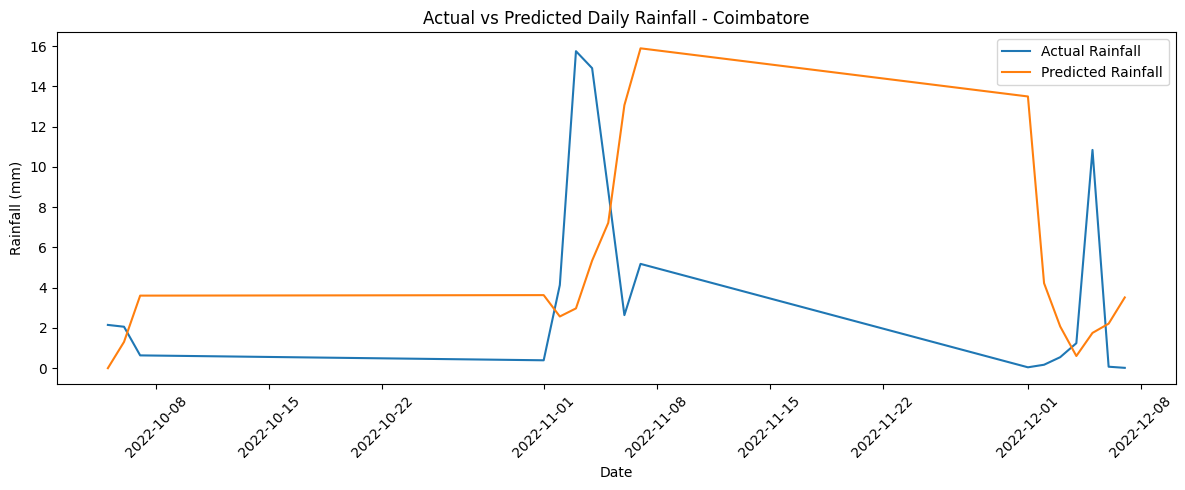

In [25]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(test_dates, actual, label='Actual Rainfall')
plt.plot(test_dates, predicted, label='Predicted Rainfall')

plt.title('Actual vs Predicted Daily Rainfall - Coimbatore')
plt.xlabel('Date')
plt.ylabel('Rainfall (mm)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:

results = pd.DataFrame({
    'Date': pd.to_datetime(test_dates),
    'Actual Rainfall (mm)': actual,
    'Predicted Rainfall (mm)': predicted
})

display(results.head(15))


,Date,Actual Rainfall (mm),Predicted Rainfall (mm)
0,2022-10-05,2.148530,0.000000
1,2022-10-06,2.058240,1.304163
2,2022-10-07,0.634903,3.603691
3,2022-11-01,0.391553,3.628544
4,2022-11-02,4.129990,2.567291
5,2022-11-03,15.745200,2.969525
6,2022-11-04,14.902100,5.341433
7,2022-11-05,8.816260,7.219420
8,2022-11-06,2.635400,13.063006
9,2022-11-07,5.180290,15.887221
